# Delayed RIM teleoperation — talk figures

Every figure of the talk, from the final sessions of E1–E4 and E6 (FIGURES_PLAN.md). Run top to bottom:
each figure is shown and saved to `figures/` (next to this notebook) as PDF (slides) and PNG.

| Figure | Message | Data |
|---|---|---|
| F1 | P-P degrades with delay; local models do not | E1, heavy direction, 0.25 Hz |
| F1b | Without a model the inertia goes unfelt, and grows with frequency | E1, T = 2.6 s |
| F2 | Under delay, contact arrives a round trip late, after a drag | E3, one contact at 850 ms |
| F3 | The same across delays | E3, 5 cm/s |
| F4 | A fixed mass cannot render a direction-dependent inertia | E2 circle |
| F5 | A mass tuned in one configuration is wrong elsewhere; RIM follows the arm | E4 reach |
| F6 | What the model misses: the arm is heavier than its URDF, plus friction | E1, T = 0 |
| F7 | Hand in the loop: P-P under delay feels the table after the lift | E6, one run each, 2.6 s |
| F7b | Hand in the loop, every delay | E6 |
| F8 | Under delay, a local model still renders a wall; P-P does not | E6, felt force vs depth |
| F9 | How stiff a wall under delay (once run) | E5 guided stiffness ladders |

Robot forces are the OSC's computed `task_wrench` (F_osc), not a force sensor. One run per condition
(E3: three contacts per run); M3–M5's agreement between T = 0 and 2.6 s serves as the repeat.

In [1]:
import json
import os
import shutil

os.environ.setdefault("JAX_PLATFORMS", "cpu")  # before anything imports JAX
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/analysis
sys.path[:0] = [str(HERE.parent / "exp"), str(HERE.parent), str(HERE.parent / "tools")]
REPO = HERE.parents[2]
for src in (REPO / "python/fr3_haptic/src", REPO / "external/adl-python/packages/experiment_logger/src"):
    sys.path.append(str(src))  # the analysis environment does not install them (their ROS-side deps)

import matplotlib.pyplot as plt  # noqa: E402, I001
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from matplotlib.lines import Line2D  # noqa: E402

import exp_metrics  # noqa: E402
import metrics as M  # noqa: E402
from common import OUT, RUN_ENDED, collect, load_table, relocate, stop_reason  # noqa: E402
from runs import load_run, surface_of  # noqa: E402

%matplotlib inline

## Configuration

In [2]:
SESSIONS = {}  # exp -> a session file, to override the latest one (e.g. "e3": OUT / "robot/e3/sessions/<time>.txt")
EXPERIMENTS = ("e1", "e2", "e3", "e4", "e6")
FIG_DIR = HERE / "figures"  # analysis/figures
FORMATS = ("pdf", "png")
MODEL_CACHE = HERE / "model_cache.json"  # the arm's Λ at the positions the figures need (committed)
FIG_DIR.mkdir(exist_ok=True)


def session(exp: str) -> Path:
    """The experiment's session file: an override from SESSIONS, else its latest one. A resumed session
    lists every condition once (the runs it reused too), so the latest is the complete, current set."""
    return SESSIONS.get(exp) or sorted((OUT / f"robot/{exp}/sessions").glob("*.txt"))[-1]


def check_session(exp: str) -> list[Path]:
    """The session's runs, after checking each ended normally and was analysed, and that no condition is
    listed twice. Interrupted tries stay on disk but are not in the session; they are only counted."""
    runs = collect([session(exp)])
    bad = [r.name for r in runs if stop_reason(r) != RUN_ENDED or not (r / "analysis/metrics.json").exists()]
    conds = [r.name[16:] for r in runs]
    dup = sorted({c for c in conds if conds.count(c) > 1})
    if bad or dup:
        raise RuntimeError(f"{exp} ({session(exp).name}): not ended/analysed {bad}, listed twice {dup}")
    tries = [r for r in (OUT / f"robot/{exp}").glob("2*_*") if r.name[16:] in conds and r not in runs]
    print(
        f"{exp}: {session(exp).name}, {len(runs)} runs, all ended and analysed ({len(tries)} superseded tries on disk)"
    )
    return runs


RUNS = {exp: check_session(exp) for exp in EXPERIMENTS}


def inertia_at(position) -> dict:
    """RIM's model at a start position (``common.start_inertia``): from ``model_cache.json``, else
    computed (needs the full robot stack: arm_client, PyRoki, pinocchio; the humble environment) and
    added to the cache. The analysis environment only reads the cache."""
    key = ",".join(f"{float(v):.4f}" for v in position)
    cache = json.loads(MODEL_CACHE.read_text()) if MODEL_CACHE.exists() else {}
    if key not in cache:
        from common import start_inertia

        d = start_inertia(position)
        cache[key] = {k: np.asarray(d[k]).tolist() for k in ("q", "Lambda", "Lambda_held", "Lambda_rim", "eigvals", "eigvecs")}
        MODEL_CACHE.write_text(json.dumps(cache, indent=1))
    return {k: np.asarray(v) for k, v in cache[key].items()}


e1: 20261026_135404.txt, 60 runs, all ended and analysed (24 superseded tries on disk)
e2: 20261026_143045.txt, 8 runs, all ended and analysed (0 superseded tries on disk)
e3: 20261026_170146.txt, 37 runs, all ended and analysed (15 superseded tries on disk)
e4: 20261026_173012.txt, 4 runs, all ended and analysed (0 superseded tries on disk)
e6: 20261027_183629.txt, 16 runs, all ended and analysed (15 superseded tries on disk)


## Style

Slide-sized figures (16:9, about half to a full slide wide), LaTeX text, one colour per method in a fixed
order. The four method colours are validated for colour-vision deficiency (all pairs ΔE ≥ 13.8 under
protan/deutan/tritan, ≥ 21 at normal vision); amber is light on white, so every series also carries a
legend or a direct label. Grey is reserved for the robot and black for references.

In [3]:
FULL_W, HALF_W = 7.0, 4.6  # [in]
METHODS = ["zoh", "proxy-god-object", "proxy-fixed-mass", "proxy-rim"]
COLORS = {
    "zoh": "#C2185B",  # M1 P-P
    "proxy-god-object": "#5B3FA8",  # M3 god-object
    "proxy-fixed-mass": "#E69F00",  # M4 fixed mass
    "proxy-rim": "#3D8EF0",  # M5 RIM
    "proxy-rim-free": "#3D8EF0",  # M5, rotation free (dashed)
}
LABELS = {
    "zoh": r"M1 P-P",
    "proxy-god-object": r"M3 God-object",
    "proxy-fixed-mass": r"M4 Fixed mass",
    "proxy-rim": r"M5 RIM",
    "proxy-rim-free": r"M5 RIM, rotation free",
}
ROBOT = "#6B6B6B"
REF = "#000000"
DELAYS = ["0", "5g", "850", "2600"]
DELAY_TICKS = {"0": "0", "5g": "5G", "850": "850 ms", "2600": "2.6 s"}

# LaTeX text if installed, else mathtext (close, not identical); FIG_USETEX=0 / 1 forces it
_usetex = os.environ.get("FIG_USETEX", "auto")
USETEX = shutil.which("latex") is not None if _usetex == "auto" else _usetex == "1"
PCT = r"\%" if USETEX else "%"

plt.rcParams.update(
    {
        "text.usetex": USETEX,
        "text.latex.preamble": r"\usepackage{amsmath}",
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "axes.titlelocation": "left",
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "0.35",
        "axes.labelcolor": "0.1",
        "xtick.color": "0.35",
        "ytick.color": "0.35",
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "axes.grid": True,
        "grid.color": "0.88",
        "grid.linewidth": 0.6,
        "legend.fontsize": 11,
        "legend.frameon": False,
        "lines.linewidth": 2.0,
        "lines.markersize": 7,
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.03,
    }
)


def delay_key(rtt) -> str:
    return str(rtt).lower() if str(rtt).lower() == "5g" else str(int(round(float(rtt))))


def delay_axis(ax, present=DELAYS) -> dict:
    """Categorical round-trip axis; returns ``delay -> x``."""
    keys = [d for d in DELAYS if d in set(present)]
    ax.set_xticks(range(len(keys)), [DELAY_TICKS[k] for k in keys])
    ax.set_xlim(-0.3, len(keys) - 0.7)
    ax.set_xlabel(r"round-trip delay $T$")
    ax.grid(axis="x", visible=False)
    return {k: i for i, k in enumerate(keys)}


def method_legend(ax, methods, loc="upper left", **kw):
    handles = [Line2D([], [], color=COLORS[m], marker="o", lw=2, label=LABELS[m]) for m in methods]
    return ax.legend(handles=handles, loc=loc, **kw)


def save(fig, name: str) -> None:
    for fmt in FORMATS:
        fig.savefig(FIG_DIR / f"{name}.{fmt}")
    print(f"saved {name}: " + ", ".join(f"{name}.{f}" for f in FORMATS))

## Data

In [4]:
tables = {}
RECOMPUTE = {"e3": exp_metrics.e3}  # E3 runs analysed before hold_latency_ms existed lack it
for exp in EXPERIMENTS:
    df = load_table(RUNS[exp], RECOMPUTE.get(exp))
    df["T"] = df.rtt.map(delay_key)
    tables[exp] = df
e1, e2, e3, e4, e6 = (tables[k] for k in ("e1", "e2", "e3", "e4", "e6"))
e1["direction"] = e1.label.str.split("_").str[0]
e3["steady"] = e3.label.fillna("").str.endswith("steady")
e2["method"] = np.where(e2.label.fillna("") == "free", "proxy-rim-free", e2.method)
e4 = e4[e4.label.fillna("") == "zdither"].reset_index(drop=True)
print({k: len(v) for k, v in tables.items()})

{'e1': 60, 'e2': 8, 'e3': 37, 'e4': 4, 'e6': 16}


## F1 — P-P degrades with delay; local models do not

RMS unfelt force $e_F$ along the motion, heavy direction of $\Lambda_0$, 0.25 Hz (the frequency where M1 is
monotonic in T: $K\,2A\lvert\sin(\omega T/2)\rvert/\sqrt2$). M3–M5 sit on the friction floor at every delay.

findfont: Failed to find font weight normal for CMU Serif, now using 500.


saved F1_eF_vs_delay: F1_eF_vs_delay.pdf, F1_eF_vs_delay.png


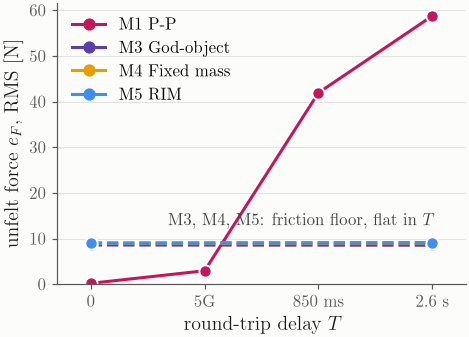

In [5]:
sub = e1[(e1.direction == "heavy") & np.isclose(e1.frequency_hz, 0.25)]
fig, ax = plt.subplots(figsize=(HALF_W, 3.4))
xs = delay_axis(ax, sub["T"])
for m in METHODS:
    s = sub[sub.method == m].set_index("T").reindex([k for k in xs if k in set(sub[sub.method == m]["T"])])
    x = [xs[k] for k in s.index]
    ls = "-" if m == "zoh" else "--"
    ax.plot(
        x, s.eF_n_rms, ls, marker="o", color=COLORS[m], ms=8, mec="white", mew=1.2, zorder=3 if m == "proxy-rim" else 2
    )
ax.set_ylabel(r"unfelt force $e_F$, RMS [N]")
ax.set_ylim(0, None)
floor = sub[(sub.method != "zoh")].eF_n_rms.mean()
ax.annotate(
    r"M3, M4, M5: friction floor, flat in $T$",
    (xs["2600"], floor),
    xytext=(0, 10),
    textcoords="offset points",
    ha="right",
    va="bottom",
    color="0.25",
    fontsize=11,
)
method_legend(ax, METHODS, loc="upper left")
fig.tight_layout()
save(fig, "F1_eF_vs_delay")

## F1b — Without a dynamic model the inertia goes unfelt, and it grows with frequency

M3–M5 at T = 2.6 s against the drive frequency, both directions of $\Lambda_0$ (heavy 14.5 kg, light 4.8 kg).
At 1 Hz heavy the M4/M5 proxy is near its coupling resonance (1.3 Hz): the robot swings 1.8× the leader.

saved F1b_eF_vs_frequency: F1b_eF_vs_frequency.pdf, F1b_eF_vs_frequency.png


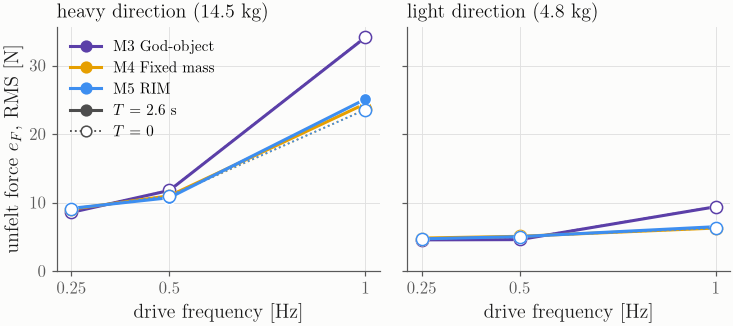

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 3.3), sharey=True)
for ax, d, title in zip(
    axes, ("heavy", "light"), ("heavy direction (14.5 kg)", "light direction (4.8 kg)")
):
    for m in METHODS[1:]:
        for T, mfc in (("2600", None), ("0", "white")):
            s = e1[(e1.direction == d) & (e1.method == m) & (e1["T"] == T)].sort_values("frequency_hz")
            ax.plot(
                s.frequency_hz,
                s.eF_n_rms,
                "-" if T == "2600" else ":",
                marker="o",
                color=COLORS[m],
                mfc=mfc or COLORS[m],
                mec=COLORS[m] if mfc else "white",
                ms=8,
                lw=2 if T == "2600" else 1.2,
            )
    ax.set_title(title)
    ax.set_xlabel("drive frequency [Hz]")
    ax.set_xticks([0.25, 0.5, 1.0], ["0.25", "0.5", "1"])
axes[0].set_ylabel(r"unfelt force $e_F$, RMS [N]")
axes[0].set_ylim(0, None)
h = [Line2D([], [], color=COLORS[m], marker="o", lw=2, label=LABELS[m]) for m in METHODS[1:]]
h += [
    Line2D([], [], color="0.3", lw=2, marker="o", label=r"$T$ = 2.6 s"),
    Line2D([], [], color="0.3", lw=1.2, ls=":", marker="o", mfc="white", label=r"$T$ = 0"),
]
axes[0].legend(handles=h, loc="upper left", fontsize=10)
fig.tight_layout()
save(fig, "F1b_eF_vs_frequency")

## F2 — Under delay, contact arrives a round trip late, after a drag

One contact (the second of the run) at T = 850 ms, approach at 5 cm/s: M1 against M5. Top: heights above the
table. Bottom: the force the operator felt and the robot's table force $-F_{osc,z}$, each at its own time.

saved F2_contact_timeseries: F2_contact_timeseries.pdf, F2_contact_timeseries.png


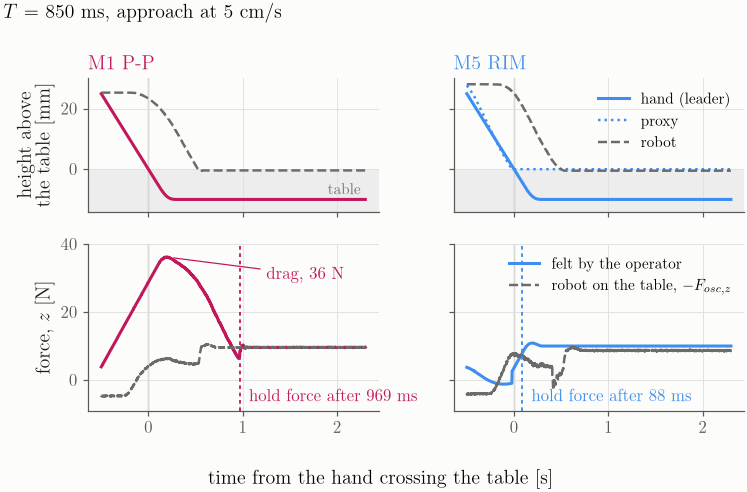

In [7]:
pick = e3[(e3["T"] == "850") & np.isclose(e3.approach_speed.astype(float), 0.05) & ~e3.steady]
fig, axes = plt.subplots(
    2, 2, figsize=(FULL_W, 4.6), sharex=True, sharey="row", gridspec_kw={"height_ratios": [1, 1.25]}
)
for j, m in enumerate(("zoh", "proxy-rim")):
    run = load_run(pick[pick.method == m].dir.iloc[0])
    contact = exp_metrics.e3(run)["per_contact"][1]
    s, tc = surface_of(run["meta"]), contact["t_cross"]
    h, rb = run["haptic"], run["robot"]
    th, tr = h.ts.to_numpy(float) - tc, rb.ts.to_numpy(float) - tc
    wh, wr = (th > -0.5) & (th < 2.3), (tr > -0.5) & (tr < 2.3)
    az, af = axes[0, j], axes[1, j]
    az.axhspan(-14, 0, color="0.93", lw=0, zorder=0)
    az.plot(th[wh], 1e3 * (h.x_l_2.to_numpy(float)[wh] - s), color=COLORS[m], label="hand (leader)")
    if m != "zoh":
        az.plot(th[wh], 1e3 * (h.proxy_x_2.to_numpy(float)[wh] - s), color=COLORS[m], lw=1.6, ls=":", label="proxy")
    az.plot(tr[wr], 1e3 * (rb.z.to_numpy(float)[wr] - s), color=ROBOT, lw=1.6, ls="--", label="robot")
    af.plot(th[wh], h.f_2.to_numpy(float)[wh], color=COLORS[m], label="felt by the operator")
    af.plot(tr[wr], -rb.fz.to_numpy(float)[wr], color=ROBOT, lw=1.6, ls="--", label=r"robot on the table, $-F_{osc,z}$")
    for ax in (az, af):
        ax.axvline(0, color="0.55", lw=0.8, zorder=1)
    hold = contact["hold_latency_ms"] / 1e3
    af.axvline(hold, color=COLORS[m], lw=1.2, ls=(0, (2, 2)))
    af.annotate(
        f"hold force after {1e3 * hold:.0f} ms",
        (hold, -5),
        xytext=(6, 0),
        textcoords="offset points",
        color=COLORS[m],
        fontsize=11,
        va="center",
    )
    az.set_title(LABELS[m], color=COLORS[m])
    if m == "zoh":
        k = np.argmax(h.f_2.to_numpy(float)[wh])
        af.annotate(
            f"drag, {h.f_2.to_numpy(float)[wh][k]:.0f} N",
            (th[wh][k], h.f_2.to_numpy(float)[wh][k]),
            xytext=(1.25, 31),
            textcoords="data",
            fontsize=11,
            color=COLORS[m],
            va="center",
            arrowprops=dict(arrowstyle="-", color=COLORS[m], lw=0.8, shrinkA=2, shrinkB=4),
        )
axes[0, 0].set_ylabel("height above\nthe table [mm]")
axes[1, 0].set_ylabel("force, $z$ [N]")
axes[0, 0].set_ylim(-14, 30)
axes[1, 0].set_ylim(-9, 40)
axes[0, 1].legend(loc="upper right", fontsize=10)
axes[1, 1].legend(loc="upper right", fontsize=10)
axes[0, 0].text(2.25, -7, "table", ha="right", va="center", color="0.45", fontsize=10)
fig.suptitle(r"$T$ = 850 ms, approach at 5 cm/s", x=0.01, ha="left", fontsize=13)
fig.supxlabel("time from the hand crossing the table [s]", fontsize=13, y=0.02)
fig.tight_layout()
save(fig, "F2_contact_timeseries")

## F3 — Contact across delays

Approach at 5 cm/s, mean of three contacts per run. Left: time from the hand crossing the table until the felt
force holds within ±20 % of its final value. Right: force felt at the crossing (drag: the delayed robot pulling
the hand back). M3–M5: 88 ms at every delay.

saved F3_contact_vs_delay: F3_contact_vs_delay.pdf, F3_contact_vs_delay.png


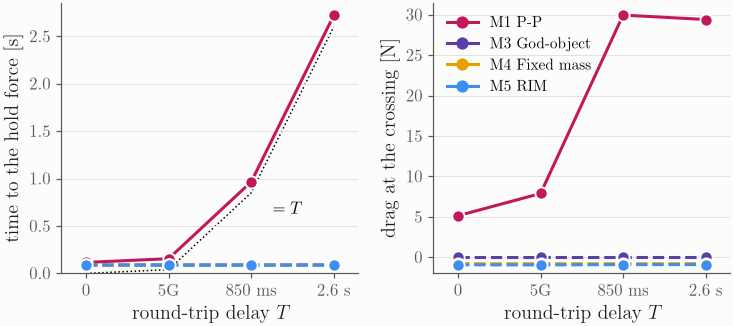

In [8]:
sub = e3[np.isclose(e3.approach_speed.astype(float), 0.05) & ~e3.steady]
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 3.3))
for ax, y, ylabel, scale in (
    (axes[0], "hold_latency_ms_mean", r"time to the hold force [s]", 1e-3),
    (axes[1], "felt_at_crossing_N_mean", r"drag at the crossing [N]", 1.0),
):
    xs = delay_axis(ax, sub["T"])
    for m in METHODS:
        s = sub[sub.method == m].set_index("T").reindex(list(xs))
        ax.plot(
            list(xs.values()),
            scale * s[y],
            "-" if m == "zoh" else "--",
            marker="o",
            color=COLORS[m],
            ms=8,
            mec="white",
            mew=1.2,
        )
    ax.set_ylabel(ylabel)
axes[0].plot([xs[k] for k in xs], [float(k.replace("5g", "40")) / 1e3 for k in xs], color=REF, lw=1, ls=":", zorder=0)
axes[0].annotate(
    r"$= T$", (xs["850"], 0.85), xytext=(14, -6), textcoords="offset points", ha="left", va="top", fontsize=11
)
axes[0].set_ylim(0, None)
axes[1].set_ylim(-2, None)
method_legend(axes[1], METHODS, loc="upper left", fontsize=10)
fig.tight_layout()
save(fig, "F3_contact_vs_delay")

## F4 — A fixed mass cannot render a direction-dependent inertia

Horizontal circle (radius 10 cm, period 2 s), T = 0. Left: the radial (centripetal) force the operator felt along
the circle; dashed: the model's $u^\top\Lambda u\,a$ at the circle's centre. M5 renders the arm's anisotropy
(twice per lap); M4 a constant $m a$; the rotation-free reduction is ~7× too light; M3 renders nothing. Right: the
centripetal force the robot needed and the operator did not feel, at both delays.

saved F4_circle_anisotropy: F4_circle_anisotropy.pdf, F4_circle_anisotropy.png


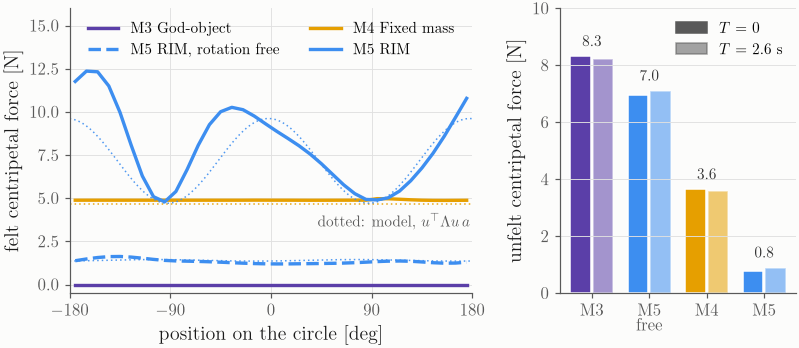

In [9]:

CENTER = [0.5, 0.0, 0.25]  # e2_circle.py
lam_c = inertia_at(CENTER)
order = ["proxy-god-object", "proxy-rim-free", "proxy-fixed-mass", "proxy-rim"]
chk = {r: exp_metrics.e2_checks(load_run(r)) for r in e2[e2["T"] == "0"].dir}
a = float(np.median([c["accel"] for c in chk.values()]))
ph = np.radians(np.linspace(-180, 180, 181))
u = -np.c_[np.cos(ph), np.sin(ph)]
model = {
    "proxy-rim": np.einsum("ij,jk,ik->i", u, lam_c["Lambda_held"][:2, :2], u) * a,
    "proxy-rim-free": np.einsum("ij,jk,ik->i", u, lam_c["Lambda"][:2, :2], u) * a,
    "proxy-fixed-mass": np.full_like(
        ph, chk[e2[(e2.method == "proxy-fixed-mass") & (e2["T"] == "0")].dir.iloc[0]]["proxy_mass"] * a
    ),
}
fig, (ax, axb) = plt.subplots(1, 2, figsize=(FULL_W + 0.6, 3.5), gridspec_kw={"width_ratios": [1.7, 1]})
for m in order:
    row = e2[(e2.method == m) & (e2["T"] == "0")].iloc[0]
    c = chk[row.dir]
    y = np.array([np.nan if v is None else v for v in c["felt_radial_by_phase"]])
    ls = "--" if m == "proxy-rim-free" else "-"
    ax.plot(c["phase_deg"], y, ls, color=COLORS[m], lw=2.2, label=LABELS[m])
    if m in model:
        ax.plot(np.degrees(ph), model[m], color=COLORS[m], lw=1, ls=(0, (1, 2)), alpha=0.9)
ax.set(
    xlabel="position on the circle [deg]",
    ylabel="felt centripetal force [N]",
    xticks=range(-180, 181, 90),
    xlim=(-180, 180),
)
ax.set_ylim(-0.5, 16)
ax.legend(loc="upper center", ncol=2, fontsize=10)
ax.text(
    178,
    model["proxy-rim"].min() - 0.6,
    r"dotted: model, $u^\top\Lambda u\,a$",
    ha="right",
    va="top",
    fontsize=10,
    color="0.35",
)
w = 0.36
for i, m in enumerate(order):
    for k, (T, alpha) in enumerate((("0", 1.0), ("2600", 0.55))):
        v = e2[(e2.method == m) & (e2["T"] == T)].eF_radial_mean.iloc[0]
        axb.bar(i + (k - 0.5) * w * 1.08, v, w, color=COLORS[m], alpha=alpha, edgecolor="white", lw=1)
    axb.text(
        i,
        e2[e2.method == m].eF_radial_mean.max() + 0.25,
        f"{e2[(e2.method == m) & (e2['T'] == '0')].eF_radial_mean.iloc[0]:.1f}",
        ha="center",
        va="bottom",
        fontsize=10,
        color="0.2",
    )
axb.set_xticks(range(len(order)), ["M3", "M5\nfree", "M4", "M5"])
axb.set_ylabel(r"unfelt centripetal force [N]")
axb.grid(axis="x", visible=False)
axb.set_ylim(0, 10)
axb.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color="0.35"), plt.Rectangle((0, 0), 1, 1, color="0.35", alpha=0.55)],
    labels=[r"$T$ = 0", r"$T$ = 2.6 s"],
    loc="upper right",
    fontsize=10,
)
fig.tight_layout()
save(fig, "F4_circle_anisotropy")

## F5 — A mass tuned in one configuration is wrong elsewhere; RIM follows the arm

A slow line outward (x 0.30 → 0.68 m at z = 0.15 m) with a 3 cm, 0.7 Hz vertical dither; masses phase-separated
at the dither frequency (friction drops out). Left: T = 2.6 s. Right: the mass the operator was not shown, both
delays.

saved F5_reach_mass: F5_reach_mass.pdf, F5_reach_mass.png


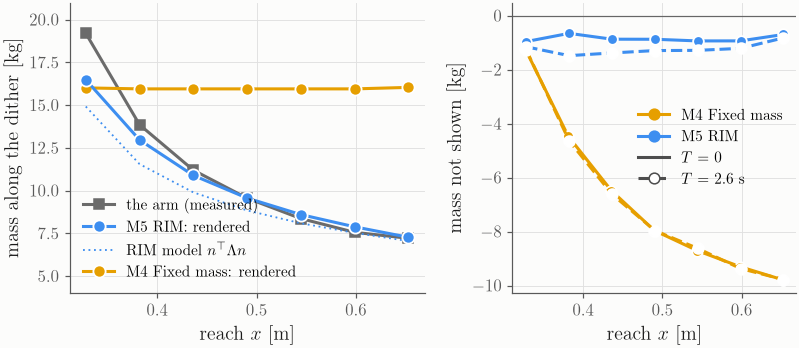

In [10]:
res4 = {r: exp_metrics.e4(load_run(r)) for r in e4.dir}
origin = {r: np.asarray(load_run(r)["meta"]["leader_origin"], float) for r in e4.dir}


def mass_rows(r):
    rows = [x for x in res4[r]["mass_by_s"] if x is not None]
    return np.array([origin[r][0] + x["s_m"] for x in rows]), rows


fig, (ax, axe) = plt.subplots(1, 2, figsize=(FULL_W + 0.6, 3.5), gridspec_kw={"width_ratios": [1.25, 1]})
for _, row in e4[e4["T"] == "2600"].iterrows():
    xs, rows = mass_rows(row.dir)
    if row.method == "proxy-rim":
        ax.plot(
            xs, [x["m_robot"] for x in rows], "-", marker="s", color=ROBOT, ms=6, label="the arm (measured)", zorder=2
        )
        ax.plot(
            xs,
            [x["m_model"] for x in rows],
            color=COLORS["proxy-rim"],
            lw=1.2,
            ls=(0, (1, 2)),
            label=r"RIM model $n^\top\Lambda n$",
        )
    ax.plot(
        xs,
        [x["m_felt"] for x in rows],
        marker="o",
        color=COLORS[row.method],
        mec="white",
        mew=1.2,
        ms=8,
        label=LABELS[row.method] + ": rendered",
        zorder=3,
    )
ax.set(xlabel=r"reach $x$ [m]", ylabel=r"mass along the dither [kg]")
h5, l5 = ax.get_legend_handles_labels()
order5 = [
    l5.index(x)
    for x in (
        "the arm (measured)",
        LABELS["proxy-rim"] + ": rendered",
        r"RIM model $n^\top\Lambda n$",
        LABELS["proxy-fixed-mass"] + ": rendered",
    )
]
ax.legend([h5[i] for i in order5], [l5[i] for i in order5], loc="lower left", fontsize=10)
ax.set_ylim(4, 21)
for _, row in e4.iterrows():
    xs, rows = mass_rows(row.dir)
    ls = "-" if row["T"] == "0" else "--"
    axe.plot(
        xs,
        [x["m_err"] for x in rows],
        ls,
        marker="o",
        color=COLORS[row.method],
        mec="white",
        mew=1.2,
        ms=7,
        mfc=COLORS[row.method] if row["T"] == "0" else "white",
    )
axe.axhline(0, color="0.4", lw=0.8)
axe.set(xlabel=r"reach $x$ [m]", ylabel="mass not shown [kg]")
h = [Line2D([], [], color=COLORS[m], marker="o", lw=2, label=LABELS[m]) for m in ("proxy-fixed-mass", "proxy-rim")]
h += [
    Line2D([], [], color="0.3", lw=2, label=r"$T$ = 0"),
    Line2D([], [], color="0.3", lw=2, ls="--", marker="o", mfc="white", label=r"$T$ = 2.6 s"),
]
axe.legend(handles=h, loc="center right", fontsize=10)
fig.tight_layout()
save(fig, "F5_reach_mass")

## F6 — What the model misses

The arm's first-harmonic impedance along the motion, $\mathrm{Re}\,Z = k - m\,\omega^2$, at T = 0 under every method
(the robot needs the same force whatever the method). The slope is the arm's effective mass: ~1.4× the held
model in both directions (rotor inertia is not in the URDF). Joint friction sets the floor of $e_F$ (Coulomb
~9 N heavy, ~4.6 N light at 0.25 Hz).

saved F6_arm_impedance: F6_arm_impedance.pdf, F6_arm_impedance.png


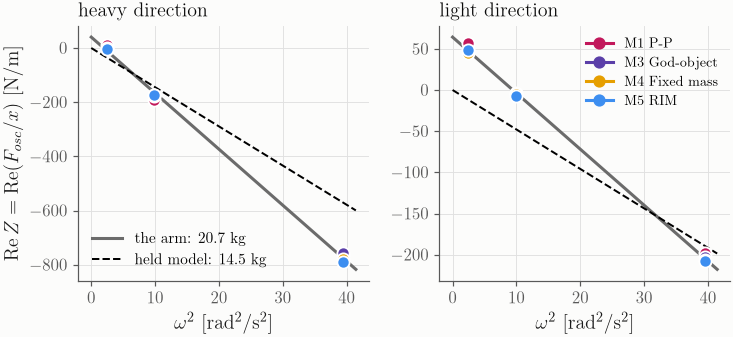

In [11]:
from e1_free_motion import START  # noqa: E402

lam0 = inertia_at(START)
dirs_n = {"heavy": lam0["eigvecs"][:, 2], "light": lam0["eigvecs"][:, 0]}
model_mass = {d: float(n @ lam0["Lambda_rim"] @ n) for d, n in dirs_n.items()}
t0 = e1[e1["T"] == "0"].copy()
t0 = t0.merge(
    pd.DataFrame([{"run": Path(r).name, **exp_metrics.e1_checks(load_run(r))} for r in t0.dir])[
        ["run", "ReZ", "coulomb_N"]
    ],
    on="run",
)
t0["w2"] = (2 * np.pi * t0.frequency_hz) ** 2
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 3.4))
for ax, d in zip(axes, ("heavy", "light")):
    g = t0[t0.direction == d]
    (k, slope), *_ = np.linalg.lstsq(np.c_[np.ones(len(g)), g.w2], g.ReZ, rcond=None)
    w2 = np.linspace(0, g.w2.max() * 1.05, 50)
    ax.plot(w2, k + slope * w2, color=ROBOT, lw=2, label=f"the arm: {-slope:.1f} kg")
    ax.plot(w2, -model_mass[d] * w2, color=REF, lw=1.3, ls="--", label=f"held model: {model_mass[d]:.1f} kg")
    for m in METHODS:
        s = g[g.method == m]
        ax.plot(s.w2, s.ReZ, "o", color=COLORS[m], ms=8, mec="white", mew=1.2, zorder=3)
    ax.set_title(f"{d} direction")
    ax.set_xlabel(r"$\omega^2$ [rad$^2$/s$^2$]")
    ax.legend(loc="lower left", fontsize=10)
axes[0].set_ylabel(r"$\mathrm{Re}\,Z = \mathrm{Re}(F_{osc}/x)$ [N/m]")
method_legend(axes[1], METHODS, loc="upper right", fontsize=9)
fig.tight_layout()
save(fig, "F6_arm_impedance")

## F7 — Hand in the loop: P-P under delay feels the table after the lift

E6, the operator following the guide (taps at 8 cm/s with a 0.3 s touch, holds of 4 s at 10 mm), T = 2.6 s:
the first tap and hold of the M1 and M5 runs. Top: the guide's reference, the hand and the robot. Bottom: the force
felt and the robot's table force.

saved F7_hand_in_the_loop: F7_hand_in_the_loop.pdf, F7_hand_in_the_loop.png


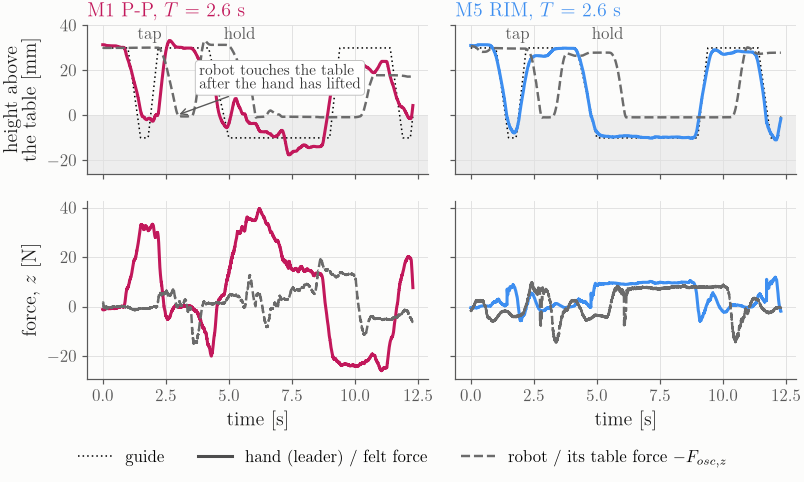

In [12]:
from fr3_haptic.guide import Guide  # noqa: E402

pick = e6[e6["T"] == "2600"]
fig, axes = plt.subplots(
    2, 2, figsize=(FULL_W + 0.6, 4.6), sharex=True, sharey="row", gridspec_kw={"height_ratios": [1, 1.2]}
)
for j, m in enumerate(("zoh", "proxy-rim")):
    run = load_run(pick[pick.method == m].dir.iloc[0])
    guide = Guide.from_args(run["meta"]["args"])
    s = surface_of(run["meta"])
    t_a = guide.contacts[0]["t_down"] - 1.0
    t_b = guide.contacts[1]["t_cross"] + 4.0 + 3.5
    h, rb = run["haptic"], run["robot"]
    th, tr = h.ts.to_numpy(float), rb.ts.to_numpy(float)
    wh, wr = (th > t_a) & (th < t_b), (tr > t_a) & (tr < t_b)
    az, af = axes[0, j], axes[1, j]
    az.axhspan(-15, 0, color="0.93", lw=0, zorder=0)
    tg = np.linspace(t_a, t_b, 600)
    az.plot(tg - t_a, 1e3 * (guide.z(tg) - s), color=REF, lw=1, ls=(0, (1, 2)), label="guide")
    az.plot(th[wh] - t_a, 1e3 * (h.x_l_2.to_numpy(float)[wh] - s), color=COLORS[m], label="hand (leader)")
    az.plot(tr[wr] - t_a, 1e3 * (rb.z.to_numpy(float)[wr] - s), color=ROBOT, lw=1.6, ls="--", label="robot")
    af.plot(th[wh] - t_a, h.f_2.to_numpy(float)[wh], color=COLORS[m], label="felt by the operator")
    af.plot(
        tr[wr] - t_a,
        -rb.fz.to_numpy(float)[wr],
        color=ROBOT,
        lw=1.6,
        ls="--",
        label=r"robot on the table, $-F_{osc,z}$",
    )
    for c in guide.contacts[:2]:
        az.text(c["t_cross"] - t_a, 34, c["kind"], ha="left", fontsize=11, color="0.35")
    if m == "zoh":  # the robot reaches the table only after the hand has left it
        zr = rb.z.to_numpy(float) - s
        k = np.flatnonzero((tr > guide.contacts[0]["t_cross"]) & (zr < 0.002))[0]
        az.annotate(
            "robot touches the table\nafter the hand has lifted",
            (tr[k] - t_a, 0),
            xytext=(tr[k] - t_a + 0.9, 12),
            fontsize=10,
            color="0.2",
            arrowprops=dict(arrowstyle="->", color="0.35", lw=0.9),
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.75", lw=0.6),
            zorder=5,
        )
    az.set_title(LABELS[m] + r", $T$ = 2.6 s", color=COLORS[m])
    af.set_xlabel("time [s]")
axes[0, 0].set_ylabel("height above\nthe table [mm]")
axes[1, 0].set_ylabel("force, $z$ [N]")
axes[0, 0].set_ylim(-26, 40)
for ax in axes[0]:
    ax.axhspan(-26, 0, color="0.93", lw=0, zorder=0)
h7 = [
    Line2D([], [], color=REF, lw=1, ls=(0, (1, 2)), label="guide"),
    Line2D([], [], color="0.3", lw=2, label="hand (leader) / felt force"),
    Line2D([], [], color=ROBOT, lw=1.6, ls="--", label=r"robot / its table force $-F_{osc,z}$"),
]
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.legend(handles=h7, loc="lower center", ncol=3, fontsize=11)
save(fig, "F7_hand_in_the_loop")

## F7b — Hand in the loop, every delay

Left: the share of taps whose force reached the operator before the hand lifted off (0.3 s touches). Right: the
unfelt force during the 4 s holds, mean over the hold. One run per condition, three taps and three holds each.

saved F7b_hand_in_the_loop_summary: F7b_hand_in_the_loop_summary.pdf, F7b_hand_in_the_loop_summary.png


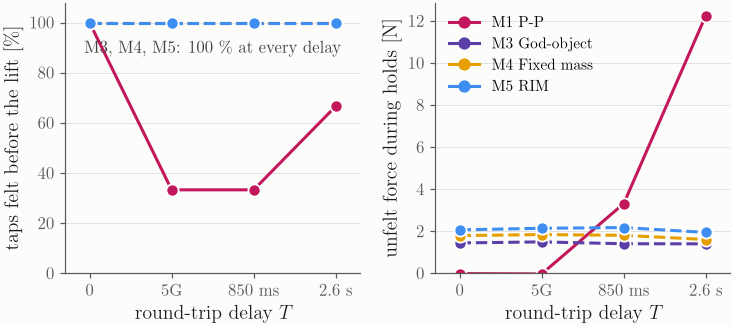

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 3.3))
for ax, y, ylabel, scale in (
    (axes[0], "tap_felt_mean", f"taps felt before the lift [{PCT}]", 100.0),
    (axes[1], "hold_eF_z_mean_mean", r"unfelt force during holds [N]", 1.0),
):
    xs = delay_axis(ax, e6["T"])
    for m in METHODS:
        s = e6[e6.method == m].set_index("T").reindex(list(xs))
        ax.plot(
            list(xs.values()),
            scale * s[y],
            "-" if m == "zoh" else "--",
            marker="o",
            color=COLORS[m],
            ms=8,
            mec="white",
            mew=1.2,
        )
    ax.set_ylabel(ylabel)
axes[0].set_ylim(0, 108)
axes[0].text(1.5, 93, f"M3, M4, M5: 100 {PCT} at every delay", ha="center", va="top", fontsize=11, color="0.25")
axes[1].set_ylim(0, None)
method_legend(axes[1], METHODS, loc="upper left", fontsize=10)
fig.tight_layout()
save(fig, "F7b_hand_in_the_loop_summary")

## F8 — Under delay, a local model still renders a wall; P-P does not

E6 (hand-held taps and holds), every sample in contact: the felt force against the hand's depth below the table.
A wall is a line through zero of slope $K$ (dashed, 1 N/mm). M5 draws the same wall at T = 0 and 2.6 s (M3 and M4
too, slopes 0.95–1.04 N/mm). P-P at 2.6 s is not a function of the depth: the force is the delayed robot's drag,
not the table.

saved F8_felt_wall: F8_felt_wall.pdf, F8_felt_wall.png


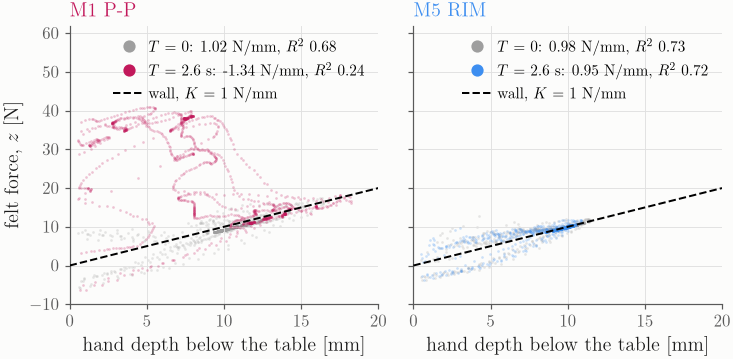

In [14]:
from exp_metrics import wall  # noqa: E402

fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 3.6), sharex=True, sharey=True)
for ax, m in zip(axes, ("zoh", "proxy-rim")):
    for T, col, size, alpha, z in (("0", "0.62", 3, 0.25, 1), ("2600", COLORS[m], 3, 0.25, 2)):
        run = load_run(e6[(e6.method == m) & (e6["T"] == T)].dir.iloc[0])
        hs = M.haptic_side(run)
        depth = 1e3 * (surface_of(run["meta"]) - hs["x_l"][:, 2])
        on = depth > 0.5
        ax.scatter(
            depth[on][::10], hs["f"][on, 2][::10], s=size, color=col, alpha=alpha, lw=0, zorder=z, rasterized=True
        )
        w = wall(run)
        ax.plot(
            [],
            [],
            "o",
            ms=7,
            color=col,
            label=rf"$T$ = {DELAY_TICKS[T]}: {w['wall_slope_N_per_mm']:.2f} N/mm, $R^2$ {w['wall_r2']:.2f}",
        )
    d = np.linspace(0, 20, 2)
    ax.plot(d, d, color=REF, lw=1.3, ls="--", zorder=3, label=r"wall, $K$ = 1 N/mm")  # K = 1000 N/m in E6
    ax.set_title(LABELS[m], color=COLORS[m])
    ax.set_xlabel("hand depth below the table [mm]")
    ax.legend(loc="upper right", fontsize=10, handletextpad=0.3)
axes[0].set_ylabel(r"felt force, $z$ [N]")
axes[0].set_xlim(0, 20)
axes[0].set_ylim(-10, 62)
fig.tight_layout()
save(fig, "F8_felt_wall")

## F9 — How stiff a wall, under delay (E5 stiffness ladders)

E5's guided ladders (hand held, E6's guide at a depth asking ~10 N at every $K$, velocity filter at the frozen 8 Hz, as E6): the
stiffness the operator measured (slope of the felt force against the depth) against the stiffness set, filled when
the step was stable, open when not. Handle stiffness is $\beta K$ (0.2 × the robot units). M1's robot stiffness is
$K$ itself, so its ladder stops at 2 N/mm. Result (2026-10-28, M3 not run): every step stable up to 8 N/mm (1.6 kN/m at the handle), the highest tested.
M5 renders the set stiffness at 2.6 s as at T = 0 (7.87 vs 7.45 N/mm at 8, R² 0.92–0.96); P-P renders it at T = 0 but
at 2.6 s has no wall (R² 0.31 → 0.00, 8 → 22 N at zero depth) although stable: stable is not transparent.

   method    T     K  stable  wall_slope_N_per_mm  wall_offset_N  wall_r2
proxy-rim    0  1000    True             1.034064      -0.300335 0.879813
proxy-rim    0  2000    True             2.005553       0.025854 0.862093
proxy-rim    0  4000    True             3.877220       0.485481 0.943661
proxy-rim    0  8000    True             7.453636       1.030838 0.960927
proxy-rim 2600  1000    True             1.031867      -0.243932 0.808908
proxy-rim 2600  2000    True             2.047410      -0.189799 0.846318
proxy-rim 2600  4000    True             3.892161       0.442169 0.946581
proxy-rim 2600  8000    True             7.869408       0.294123 0.918109
      zoh    0  1000    True             1.007329       1.541147 0.755578
      zoh    0  2000    True             1.929744       3.290541 0.812514
      zoh 2600  1000    True             0.589158       8.180172 0.306512
      zoh 2600  2000    True            -0.181402      22.008760 0.004674
proxy-rim    0 12000    True          

saved F9_stiffness_ladder: F9_stiffness_ladder.pdf, F9_stiffness_ladder.png


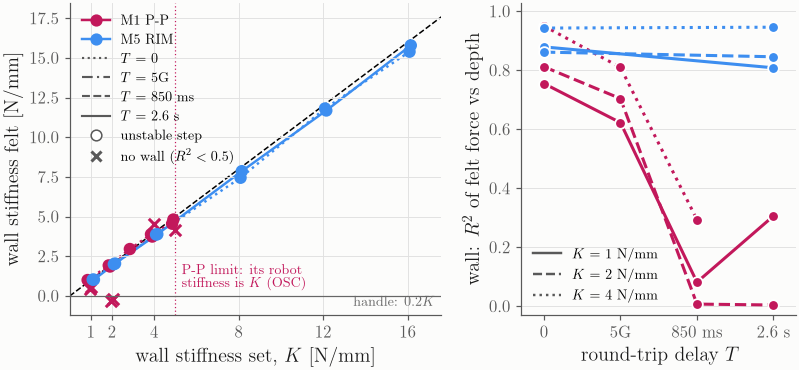

In [15]:
KMAX_CSV = OUT / "robot/e5/kmax.csv"


def ladder_table(csv_path=KMAX_CSV) -> pd.DataFrame:
    """The guided K steps: the latest run of each (method, delay, K), its verdict and its wall."""
    if not Path(csv_path).exists():
        return pd.DataFrame()
    steps = pd.read_csv(csv_path)
    steps["run"] = steps.run.map(lambda r: str(relocate(r)))  # recorded paths, wherever the data now is
    steps = steps[steps.grip == "guided"].sort_values("run").drop_duplicates(["method", "rtt", "K"], keep="last")
    walls = [wall(load_run(r)) for r in steps.run]
    return steps.assign(T=steps.rtt.map(delay_key), **pd.DataFrame(walls, index=steps.index))


WALL_R2_MIN = 0.5  # below this R² of felt force vs depth, the contact is not a wall: no slope to read
LADDER_LS = {"0": ":", "5g": (0, (5, 2, 1, 2)), "850": "--", "2600": "-"}  # one line style per delay


def plot_ladder(steps: pd.DataFrame):
    """Left: the stiffness felt against the stiffness set, every ladder. Right: how much of a wall it was
    (R² of the felt force against the depth) against the delay, at the stiffnesses P-P reaches."""
    fig, (ax, axr) = plt.subplots(1, 2, figsize=(FULL_W + 0.6, 3.7), gridspec_kw={"width_ratios": [1.35, 1]})
    top = 1.1 * steps.K.max() / 1e3
    ax.plot([0, top], [0, top], color=REF, lw=1, ls="--", zorder=0, label="felt = set")
    series = list(steps.groupby(["method", "T"], sort=False))
    series.sort(key=lambda s: (METHODS.index(s[0][0]), DELAYS.index(s[0][1])))
    for i, ((m, T), g) in enumerate(series):
        g = g.sort_values("K")
        x = g.K / 1e3 + 0.06 * (i - (len(series) - 1) / 2)  # side by side where the ladders coincide
        wall_ok = (g.wall_r2 >= WALL_R2_MIN).to_numpy()
        y = g.wall_slope_N_per_mm.where(wall_ok)  # a gap where there is no wall: no slope to connect
        ax.plot(x, y, linestyle=LADDER_LS.get(T, "-"), color=COLORS[m], lw=1.6, zorder=1)
        ax.scatter(x[wall_ok], g.wall_slope_N_per_mm[wall_ok], s=45, zorder=2, linewidths=1.4, edgecolors=COLORS[m],
                   facecolors=[COLORS[m] if st else "white" for st in g.stable[wall_ok]])
        ax.scatter(x[~wall_ok], g.wall_slope_N_per_mm[~wall_ok], s=55, zorder=2, marker="x", linewidths=2, color=COLORS[m])
    if (steps.method == "zoh").any():
        kmax_pp = steps[(steps.method == "zoh") & steps.stable].K.max() / 1e3
        ax.axvline(kmax_pp, color=COLORS["zoh"], lw=0.8, ls=(0, (1, 2)), zorder=0)
        ax.text(
            kmax_pp + 0.3,
            0.02 * top,
            "P-P limit: its robot\nstiffness is $K$ (OSC)",
            fontsize=9,
            color=COLORS["zoh"],
            va="bottom",
            ha="left",
        )
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set(xlabel=r"wall stiffness set, $K$ [N/mm]", ylabel="wall stiffness felt [N/mm]", xlim=(0, top))
    ax.set_xticks(sorted(set(steps.K / 1e3) & {1, 2, 4, 8, 12, 16}))
    h = [
        Line2D([], [], color=COLORS[m], marker="o", lw=1.6, label=LABELS[m]) for m in METHODS if m in set(steps.method)
    ]
    h += [
        Line2D([], [], color="0.35", lw=1.4, linestyle=LADDER_LS[T], label=r"$T$ = " + DELAY_TICKS[T])
        for T in DELAYS
        if T in set(steps["T"])
    ]
    if not steps.stable.all():
        h.append(Line2D([], [], color="0.35", marker="o", mfc="white", ls="none", label="unstable step"))
    if (steps.wall_r2 < WALL_R2_MIN).any():
        h.append(Line2D([], [], color="0.35", marker="x", mew=2, ls="none", label=rf"no wall ($R^2 < {WALL_R2_MIN:g}$)"))
    ax.legend(handles=h, loc="upper left", fontsize=9)
    ax.text(0.98, 0.03, r"handle: $0.2K$", transform=ax.transAxes, ha="right", fontsize=9, color="0.4")
    # right: the wall's quality against the delay
    xs = delay_axis(axr, steps["T"])
    for m in METHODS:
        for k, ls in ((1000, "-"), (2000, "--"), (4000, ":")):
            g = steps[(steps.method == m) & (steps.K == k)].set_index("T").reindex(list(xs)).dropna(subset=["wall_r2"])
            if g.empty:
                continue
            axr.plot(
                [xs[t] for t in g.index],
                g.wall_r2,
                linestyle=ls,
                marker="o",
                color=COLORS[m],
                ms=7,
                mec="white",
                mew=1.2,
            )
    axr.set_ylabel(r"wall: $R^2$ of felt force vs depth")
    axr.set_ylim(-0.03, 1.03)
    axr.legend(
        handles=[
            Line2D([], [], color="0.35", lw=1.6, label=r"$K$ = 1 N/mm"),
            Line2D([], [], color="0.35", lw=1.6, ls="--", label=r"$K$ = 2 N/mm"), Line2D([], [], color="0.35", lw=1.6, ls=":", label=r"$K$ = 4 N/mm"),
        ],
        loc="lower left",
        fontsize=9,
    )
    fig.tight_layout()
    return fig


ladder = ladder_table()
if ladder.empty:
    print("no guided E5 ladder yet: run exp/e5_kmax.py, then this cell")
else:
    print(
        ladder[["method", "T", "K", "stable", "wall_slope_N_per_mm", "wall_offset_N", "wall_r2"]].to_string(index=False)
    )
    save(plot_ladder(ladder), "F9_stiffness_ladder")